# 10 — Potencia del criterio D16: intervalos independientes frente a diferencia pareada

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`docs/avances/06-jss-metodologia.md`](../docs/avances/06-jss-metodologia.md) (D16, §1) ·
[`src/afg/experiments/analysis.py`](../src/afg/experiments/analysis.py) ·
[`src/afg/experiments/power.py`](../src/afg/experiments/power.py)

---

> **Estado: simulación con datos sintéticos.** No se corrió ningún experimento ni ningún modelo, y
> no existe ninguna corrida de evaluación (ADR 0005): todo lo que sigue sale de experimentos
> **inventados por computador**, cuya verdad se fija de antemano. Por eso ninguna cifra de este
> notebook es un resultado de la tesis: son propiedades del **criterio de decisión**, no de los
> sistemas C1, C2 o C3.

## Para qué sirve este análisis

El criterio de éxito del proyecto (D16, prerregistrado el 2026-10-13) dice que la hipótesis se
respalda si el intervalo bootstrap del 95 % de C2 queda por encima del de C1 **sin solaparse**,
en la corrección de respuesta del estrato E3. La frase admite dos lecturas, y la elección entre
ellas cambia mucho la probabilidad de poder concluir algo con las 25 preguntas mínimas de E3. Este
notebook mide esa diferencia **antes** de correr la evaluación, con el mismo código de intervalos
que usará el análisis real, para que la decisión descanse en evidencia y no en preferencia.

Cuatro términos que se usan en todo el notebook:

- **Intervalo bootstrap del 95 %**: un rango de valores plausibles para una cifra, obtenido
  repitiendo muchas veces el cálculo sobre muestras de las mismas preguntas tomadas al azar con
  reposición. Un intervalo ancho dice que la cifra es incierta.
- **Diseño pareado**: C1 y C2 responden **las mismas preguntas**. Una pregunta difícil lo es para
  las dos condiciones, de modo que lo informativo es la diferencia dentro de cada pregunta, no el
  nivel general de cada condición.
- **Potencia**: la probabilidad de que el criterio declare «respaldada» cuando la diferencia
  verdadera existe. Una potencia de 80 % significa que, en 100 experimentos así, el criterio
  detecta la diferencia en 80.
- **Falso positivo**: declarar «respaldada» cuando en realidad no hay diferencia. Se mide con una
  diferencia verdadera de cero. Un criterio razonable lo mantiene por debajo de alrededor del 5 %.

---

# 1. Los dos criterios que se comparan

Ambos usan, por pregunta, el promedio de las 3 corridas (valor entre 0 y 1) y remuestrean
**preguntas**, nunca respuestas sueltas, como ya hace el análisis (`analysis.py`).

| | Criterio | Se declara «respaldada» cuando |
|---|---|---|
| (a) | **No solapamiento** (lectura literal de D16) | el intervalo del 95 % de C2 y el de C1, calculados cada uno por separado, no se tocan y el de C2 está arriba |
| (b) | **Diferencia pareada** | el intervalo del 95 % de la diferencia C2 − C1, calculada pregunta por pregunta, queda por encima de 0 |

La diferencia entre (a) y (b) es esta. En (a), cada condición lleva su propia incertidumbre y esa
incertidumbre incluye lo difícil o fácil que es el conjunto de preguntas. Como C1 y C2 responden
las mismas preguntas, esa parte es común y en (b) se cancela: el intervalo de la diferencia solo
recoge el ruido que de verdad separa a las dos condiciones.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from afg.eda.tables import format_thousands
from afg.experiments.power import (
    PowerScenario,
    false_positive_range,
    power_by_question_count,
    power_settings_from_config,
    power_table,
    scenarios_from_config,
    score_correlation,
    simulate_grid,
)
from afg.shared.config import load_experiments_config

pd.set_option("display.width", 170)

CONFIG = load_experiments_config()
SETTINGS = power_settings_from_config()
GRID = CONFIG["power_simulation"]
print("Experimentos simulados por escenario :", SETTINGS.n_simulations)
print(
    "Remuestreos bootstrap en la simulación:",
    SETTINGS.n_resamples,
    "(el análisis real usa",
    CONFIG["evaluation"]["bootstrap_resamples"],
    ")",
)
print("Confianza de los intervalos            :", SETTINGS.confidence_level)
print("Semilla                                :", SETTINGS.seed)
print("Corridas por pregunta                  :", CONFIG["shared_budget"]["runs_per_config"])
print(
    "Preguntas (n)                          :",
    GRID["n_questions"],
    "(el mínimo de E3 es",
    CONFIG["question_bank"]["min_questions"],
    ")",
)
print("Exactitud base de C1                   :", GRID["base_accuracies"])
print("Diferencia verdadera C2 - C1           :", GRID["differences"])
print("Dispersión de la dificultad            :", GRID["difficulty_sd"])

# Reference scenario quoted in the prose: the E3 minimum size, the middle base accuracy and the
# moderate spread of the shared difficulty. All three must belong to the simulated grid.
N_REF = CONFIG["question_bank"]["min_questions"]
BASE_REF = 0.5
SD_REF = 1.0
COMPARED_DIFFERENCES = (0.15, 0.20)
assert N_REF in GRID["n_questions"] and BASE_REF in GRID["base_accuracies"]
assert SD_REF in GRID["difficulty_sd"]
assert set(COMPARED_DIFFERENCES) <= set(GRID["differences"])

Experimentos simulados por escenario : 1000
Remuestreos bootstrap en la simulación: 300 (el análisis real usa 10000 )
Confianza de los intervalos            : 0.95
Semilla                                : 42
Corridas por pregunta                  : 3
Preguntas (n)                          : [25, 40, 50] (el mínimo de E3 es 25 )
Exactitud base de C1                   : [0.4, 0.5, 0.6]
Diferencia verdadera C2 - C1           : [0.0, 0.1, 0.15, 0.2, 0.3]
Dispersión de la dificultad            : [0.0, 1.0, 2.0]


---

# 2. Cómo se simula un experimento

Un experimento simulado se arma así, con la verdad fijada de antemano:

1. Se inventan `n` preguntas. Cada una tiene una **dificultad** propia, la **misma para C1 y para
   C2**: es lo que representa que algunas preguntas son más fáciles que otras para cualquier
   sistema. La dificultad se reparte con forma de campana; su dispersión es un parámetro
   (`difficulty_sd`) y se prueban tres valores: 0 (no hay dificultad compartida), 1 (moderada) y 2
   (marcada).
2. La exactitud promedio de C1 se fija en 0,4, 0,5 o 0,6, y la de C2 es esa más la diferencia
   verdadera (0; 0,10; 0,15; 0,20 o 0,30). Los puntos de partida se calibran para que **el promedio
   sobre las preguntas** coincida exactamente con esos valores.
3. Cada condición responde cada pregunta 3 veces; cada corrida acierta o falla con la
   probabilidad de esa pregunta, y las 3 corridas se promedian.
4. Sobre ese experimento se aplican (a) y (b) con `bootstrap_mean_interval`, **la misma función**
   que calcula los intervalos del informe real. Esto se repite 1.000 veces por escenario; la
   proporción de veces que cada criterio declara «respaldada» es su potencia (o su tasa de falso
   positivo si la diferencia verdadera es 0).

**Qué tan «realista» es la correlación entre condiciones.** La dispersión de la dificultad es
una suposición, porque no hay datos de evaluación para estimarla. Se muestra cuánta correlación
produce cada valor entre los puntajes observados de C1 y C2 por pregunta (ya con el ruido de
solo 3 corridas):

In [2]:
correlations = pd.DataFrame(
    [
        {
            "dispersión de la dificultad": sd,
            "correlación C1-C2 por pregunta": round(
                score_correlation(PowerScenario(25, 3, 0.5, 0.15, sd), seed=SETTINGS.seed), 2
            ),
        }
        for sd in GRID["difficulty_sd"]
    ]
)
correlations.set_index("dispersión de la dificultad")

,correlación C1-C2 por pregunta
dispersión de la dificultad,
0.0,-0.00
1.0,0.36
2.0,0.62


Con dispersión 0 no hay dificultad compartida y la correlación es nula: ese caso es el **piso**
para la ventaja del diseño pareado. Con 1 o 2 hay una correlación moderada o alta. En una tarea
como esta, donde las preguntas de E3 piden reconstruir cómo cambió una decisión y algunas
involucran cambios más enredados que otras, una dificultad compartida es lo esperable; por eso
las cifras de cabecera usan dispersión 1 y las otras dos acotan el rango.

---

# 3. Corrida de la simulación

La rejilla completa son 135 escenarios (3 tamaños, 3 dispersiones, 3 exactitudes base y 5
diferencias). Se calcula en paralelo; el resultado no depende del número de procesos.

In [3]:
SCENARIOS = scenarios_from_config()
RESULTS = simulate_grid(SCENARIOS, SETTINGS, workers=min(8, os.cpu_count() or 1))
TABLE = pd.DataFrame(
    [
        {
            "n": r.scenario.n_questions,
            "dispersión": r.scenario.difficulty_sd,
            "base": r.scenario.base_accuracy,
            "diferencia": r.scenario.difference,
            "no solapamiento (a)": r.power_nonoverlap,
            "diferencia pareada (b)": r.power_paired,
        }
        for r in RESULTS
    ]
)
print(len(TABLE), "escenarios,", SETTINGS.n_simulations, "experimentos simulados cada uno")

135 escenarios, 1000 experimentos simulados cada uno


---

# 4. Falsos positivos: ¿alguno de los criterios declara éxito cuando no hay diferencia?

Con diferencia verdadera 0, la proporción de experimentos declarados «respaldada» es la tasa de
falso positivo. Se muestra el máximo y el mínimo sobre los 27 escenarios con diferencia 0.

In [4]:
FP = false_positive_range(RESULTS)
fp = pd.DataFrame(
    {
        "no solapamiento (a)": [FP.nonoverlap_min, FP.nonoverlap_max],
        "diferencia pareada (b)": [FP.paired_min, FP.paired_max],
    },
    index=["mínimo", "máximo"],
)
print("Escenarios con diferencia 0:", FP.n_scenarios)
(fp * 100).round(1).rename_axis("falso positivo (%)")

Escenarios con diferencia 0: 27


,no solapamiento (a),diferencia pareada (b)
falso positivo (%),,
mínimo,0.0,2.5
máximo,0.8,4.5


Los dos criterios quedan por debajo del 5 %. El de no solapamiento queda casi en 0 %, y esto es
una propiedad conocida: exigir que dos intervalos del 95 % no se toquen equivale a una prueba
mucho más exigente que el 5 % (alrededor de 0,5 %), así que rara vez declara éxito, con o sin
diferencia real. El pareado queda entre el 2 % y el 5 %, cerca de lo que corresponde a un
intervalo del 95 % mirado de un solo lado (2,5 %); su valor puede superar levemente ese 2,5 %
porque con 25 preguntas el bootstrap por percentiles es algo estrecho.

Los falsos positivos son entonces comparables y ninguno excede el 5 %. La diferencia entre los
criterios está en la potencia.

---

# 5. Potencia con el mínimo de E3 (n = 25), exactitud base de C1 = 0,5

Cada fila es un criterio y cada columna la diferencia verdadera entre C2 y C1. La columna 0,00 es
el falso positivo; las demás son potencia. Un 50 % significa que, en la mitad de los
experimentos así, el criterio declara «respaldada»; el resto da «no concluyente».

In [5]:
CRITERION_LABEL = {"nonoverlap": "(a) no solapamiento", "paired": "(b) diferencia pareada"}


def spanish_labels(table):
    """Presentation only: Spanish names for the index of a power table."""
    return table.rename(index=CRITERION_LABEL, level="criterion").rename_axis(
        index={"difficulty_sd": "dispersión", "criterion": "criterio"}
    )


print(
    "Porcentaje de experimentos declarados «respaldada» "
    f"(n = {N_REF}, exactitud base de C1 = {format_thousands(BASE_REF, 1)})"
)
spanish_labels(power_table(RESULTS, N_REF, BASE_REF))

Porcentaje de experimentos declarados «respaldada» (n = 25, exactitud base de C1 = 0,5)


+0.00  +0.10  +0.15  +0.20  +0.30
dispersión criterio                                                 
0.0        (a) no solapamiento       0.8    6.3   21.5   41.7   87.9
           (b) diferencia pareada    2.6   28.2   50.3   75.4   96.7
1.0        (a) no solapamiento       0.0    2.8   10.4   27.8   79.5
           (b) diferencia pareada    3.3   31.5   57.5   79.5   98.3
2.0        (a) no solapamiento       0.0    0.2    2.5   12.6   64.2
           (b) diferencia pareada    3.6   42.3   71.1   88.7   99.8

Lectura de las filas con dispersión 1 (moderada):

- Con una diferencia verdadera de **+0,15**, el criterio (a) declara «respaldada» en 10,4 % de los
  experimentos y el (b) en 57,5 %.
- Con **+0,20**, (a) lo hace en 27,8 % y (b) en 79,5 %.
- Con **+0,30**, (a) en 79,5 % y (b) en 98,3 %.

Con dispersión 0, sin ninguna ventaja del diseño pareado, (b) sigue superando a (a) (50,3 % frente
a 21,5 % con +0,15; 75,4 % frente a 41,7 % con +0,20). Con dispersión 2 la brecha se agranda: 71,1 %
frente a 2,5 % con +0,15, y 88,7 % frente a 12,6 % con +0,20. Es decir, **cuanto más comparten
dificultad las condiciones, más pierde el criterio de no solapamiento y más gana el pareado**.

Con n = 25 y dispersión 1, ningún criterio llega al 80 % de potencia con +0,15 (57,5 % el
pareado y 10,4 % el de no solapamiento). Con +0,20, el pareado alcanza **79,5 %**, a medio
punto del 80 %, y el de no solapamiento 27,8 %; con dispersión 0 el pareado queda en 75,4 % y con
dispersión 2 llega a 88,7 %. El mínimo de E3 es ajustado incluso para el criterio pareado.

---

# 6. La misma comparación en gráfico

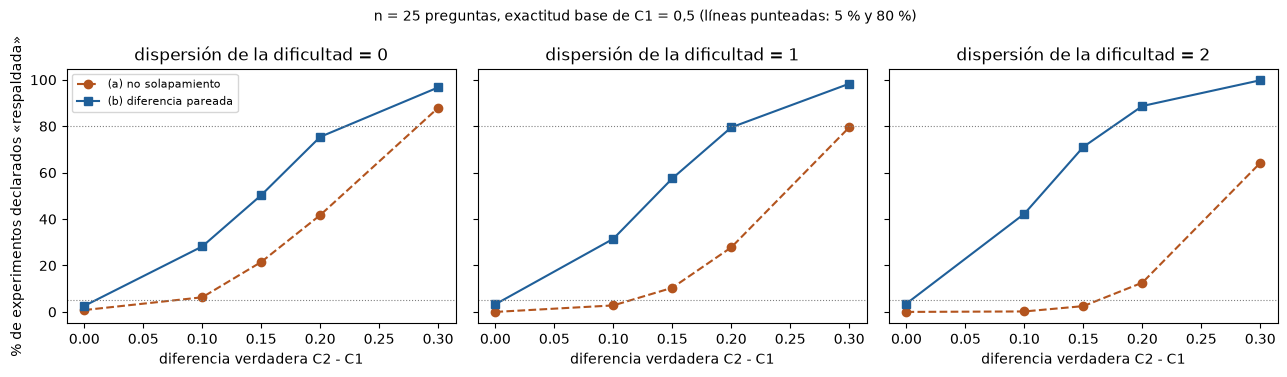

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, sd in zip(axes, GRID["difficulty_sd"], strict=True):
    subset = TABLE[
        (TABLE["n"] == 25) & (TABLE["base"] == 0.5) & (TABLE["dispersión"] == sd)
    ].sort_values("diferencia")
    ax.plot(
        subset["diferencia"],
        100 * subset["no solapamiento (a)"],
        "o--",
        color="#b3541e",
        label="(a) no solapamiento",
    )
    ax.plot(
        subset["diferencia"],
        100 * subset["diferencia pareada (b)"],
        "s-",
        color="#1f5f99",
        label="(b) diferencia pareada",
    )
    ax.axhline(80, color="grey", lw=0.8, ls=":")
    ax.axhline(5, color="grey", lw=0.8, ls=":")
    ax.set_title(f"dispersión de la dificultad = {sd:g}")
    ax.set_xlabel("diferencia verdadera C2 - C1")
axes[0].set_ylabel("% de experimentos declarados «respaldada»")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    "n = 25 preguntas, exactitud base de C1 = 0,5 (líneas punteadas: 5 % y 80 %)", fontsize=10
)
fig.tight_layout()
plt.show()

---

# 7. Otras exactitudes base de C1 (n = 25, dispersión 1)

La conclusión no depende de que C1 acierte la mitad de las veces.

In [7]:
for base in GRID["base_accuracies"]:
    print(f"\nExactitud base de C1 = {base}")
    table = spanish_labels(power_table(RESULTS, N_REF, base))
    print(table.xs(SD_REF, level="dispersión").to_string())


Exactitud base de C1 = 0.4
                        +0.00  +0.10  +0.15  +0.20  +0.30
criterio                                                 
(a) no solapamiento       0.0    2.4    9.0   24.4   72.6
(b) diferencia pareada    4.0   32.6   57.6   78.6   97.8

Exactitud base de C1 = 0.5
                        +0.00  +0.10  +0.15  +0.20  +0.30
criterio                                                 
(a) no solapamiento       0.0    2.8   10.4   27.8   79.5
(b) diferencia pareada    3.3   31.5   57.5   79.5   98.3

Exactitud base de C1 = 0.6
                        +0.00  +0.10  +0.15  +0.20  +0.30
criterio                                                 
(a) no solapamiento       0.1    3.8   13.8   36.6   91.1
(b) diferencia pareada    4.5   34.9   61.3   84.0   99.9


---

# 8. Efecto de tener más preguntas (diferencia +0,15 y +0,20, dispersión 1, base 0,5)

Si el banco de E3 llegara a más de 25 preguntas, ¿cuánto ayuda?

In [8]:
BY_N = power_by_question_count(
    RESULTS, base=BASE_REF, difficulty_sd=SD_REF, differences=COMPARED_DIFFERENCES
)
(
    BY_N[["paired", "nonoverlap"]]
    .rename(
        columns={"paired": "diferencia pareada (b)", "nonoverlap": "no solapamiento (a)"}, level=0
    )
    .rename_axis(index="preguntas (n)", columns=[None, "diferencia"])
)

diferencia pareada (b)       no solapamiento (a)      
diferencia                      0.15  0.20                0.15  0.20
preguntas (n)                                                       
25                              57.5  79.5                10.4  27.8
40                              75.7  93.8                17.4  49.1
50                              83.5  97.2                28.4  65.5

Con 40 preguntas el criterio pareado supera el 90 % con +0,20 (93,8 %) y se acerca al 80 % con
+0,15 (75,7 %); con 50, pasa del 80 % también con +0,15 (83,5 %). El de no solapamiento sigue por
debajo del 80 % en esos casos incluso con 50 preguntas (28,4 % con +0,15 y 65,5 % con +0,20).

---

# 9. Límites de esta simulación

- **Es un modelo, no la realidad.** Las respuestas se tratan como aciertos y fallos independientes
  dentro de la dificultad de cada pregunta. La dispersión de la dificultad no se pudo estimar, de
  ahí el rango de valores probado. La conclusión comparativa se mantiene en todo el rango, incluida
  la ausencia de dificultad compartida.
- **Menos remuestreos que el análisis real.** La simulación usa 300 remuestreos bootstrap por
  intervalo y el análisis real usará 10.000, para que 135.000 experimentos simulados sean
  tratables. Eso agrega algo de ruido a los límites de cada intervalo, pero no sesga la
  comparación entre criterios, que usan los mismos remuestreos.
- **Error de la propia simulación.** Cada cifra es una proporción sobre 1.000 experimentos; su
  error es de a lo más alrededor de 1,6 puntos porcentuales. Diferencias de uno o dos puntos no
  se interpretan.
- **Una sola métrica.** Solo se estudia la corrección de respuesta en E3, que es la del criterio
  principal. El resto de los resultados es descriptivo y no usa este criterio.
- **La diferencia verdadera es desconocida.** La potencia de cada criterio depende de ella.
  No se afirma que exista una diferencia de +0,15 ni de +0,20: son valores de referencia para ver
  cómo se comporta cada regla.

---

# 10. Qué se concluye

1. **Ambos criterios mantienen los falsos positivos bajo el 5 %** en los 27 escenarios sin
   diferencia (el de no solapamiento, casi en 0 %; el pareado, entre 2 % y 5 %).
2. **El criterio pareado tiene mucha más potencia que el de no solapamiento** con el mismo
   número de preguntas, en las tres exactitudes base, en las tres dispersiones de la dificultad y
   en los tres tamaños. Con 25 preguntas, dispersión moderada y una mejora verdadera de 15 a 20
   puntos, detecta la diferencia en 58 % a 80 % de los experimentos, frente a 10 % a 28 % del
   criterio de no solapamiento.
3. **La lectura literal de D16 haría casi imposible concluir** con el mínimo de 25 preguntas de E3
   salvo diferencias muy grandes (+0,30), aun cuando exista una mejora real y apreciable.
4. Por lo tanto, la simulación **respalda** declarar como criterio principal que el intervalo del
   95 % de la diferencia pareada C2 − C1 en E3 quede por encima de 0, y conservar el no
   solapamiento como cifra de robustez. Esta es una enmienda de un criterio prerregistrado, hecha
   antes de correr cualquier evaluación y con la evidencia aquí presente; queda registrada en el
   [ADR 0010](../docs/decisions/0010-adr-decisiones-del-analisis-del-experimento-b.md).
5. Con 25 preguntas ni siquiera el criterio pareado alcanza el 80 % de potencia ante una mejora de
   15 puntos: si el banco de E3 permite más preguntas, conviene aprovecharlo.